# Examples of Superposition 1: Superposition in space

Solutions for confined aquifers represent solutions to "linear homogeneous" PDEs, meaning that they can be added together to produce new solutions to the groundwater flow equation.

In this notebook, we show a few examples of superposition that are useful for representing common flow conditions. We begin by defining each of the groundwater flow solutions as functions, where we have added capabilities to calculate both the head change and the depth integrated discharge vector (-T dh/dx, -T dh/dy).

In [1]:
# GEOSCI-627 Class 15

#Import needed modules
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

from scipy.integrate import quad

In [2]:
#Definitions of all solutions to be used, each presented in terms of head change
#relative to an initial value. In addition to outputting the head change, 
#each function outputs the depth-integrated discharge (-T*dh/dx, -T*dh/dy)

def WellFunc(u):
    Wu = sp.special.exp1(u)
    return Wu

def Regional_dh(Rx, Ry, T,x0, y0, x, y):
    dh = -Rx/T*(x-x0) + -Ry/T*(y-y0)
    qix = Rx
    qiy = Ry
    return dh, qix, qiy

def Thiem_dh(Q, T, xw, yw, x0, y0, x, y):
    r0 = ((x0-xw)**2 + (y0-yw)**2)**(1/2)
    r = ((x-xw)**2 + (y-yw)**2)**(1/2)
    dh = Q/(2*np.pi*T)*(np.log(r) - np.log(r0))
    qix = -Q/(2*np.pi)*((x-xw)/(r**2))
    qiy = -Q/(2*np.pi)*((y-yw)/(r**2))
    return dh, qix, qiy

def Theis_dh(Q, T, S, xw, yw, x, y, t):
    r = ((x-xw)**2 + (y-yw)**2)**(1/2)
    u = (S*r**2)/(4*T*t)
    Wu = WellFunc(u)
    #the np.where function is used to return a drawdown of 0 before t = 0
    dh = np.where(u > 0, -Q/(4*np.pi*T)*Wu, 0)
    qix = np.where(u > 0, -Q/(2*np.pi)*((x-xw)/(r**2))*np.exp(-u), 0)
    qiy = np.where(u > 0, -Q/(2*np.pi)*((y-yw)/(r**2))*np.exp(-u), 0)
    return dh, qix, qiy

## Example 1: A well in regional flow

Experiment with the case below to see how regional flow and a pumping well interact. A key finding from this combination of solutions is that there is a defined "capture zone" that a well will receive water from. Outside of this zone, groundwater flows past the well

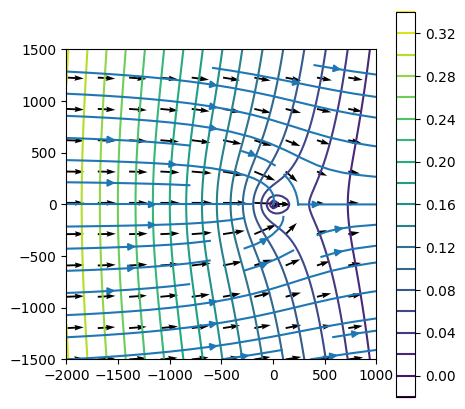

In [3]:
#Choose the range of space across which you want to plot your function 
#(2-D Solutions only)
x_coords = np.linspace(-2000,1000,100)
y_coords = np.linspace(-1500,1500,100)
xc,yc = np.meshgrid(x_coords,y_coords)

# Location at which we want head change to be zero
x0, y0 = 1000, 0

#Aquifer properties
T = 10 #m^2/day

# Well and regional flow properties
#EDIT: Try setting the regional flow rate to zero to check the flow field with only a well
Rx = 1e-3 #m^2/day
Ry = 0 #m/day

#EDIT: Try setting the well flowrate to zero to check the aquifer with only regional flow
xw, yw = 0, 0 #m
Q = 1.5 #m^3/day

well_dh, well_qix, well_qiy = Thiem_dh(Q,T,xw,yw,x0,y0,xc,yc)
regional_dh, regional_qix, regional_qiy = Regional_dh(Rx,Ry,T,x0,y0,xc,yc)

dh_total = well_dh + regional_dh
qix_total = well_qix + regional_qix
qiy_total = well_qiy + regional_qiy

# Create a figure object and axis object
fig, ax = plt.subplots(figsize=(5, 5))
#Add a contour plot to the axes
contp = ax.contour(xc, yc, dh_total,levels=20)
strmp = ax.streamplot(xc, yc, qix_total, qiy_total, density=0.5)
qfreq = 10
quiv = ax.quiver(xc[::qfreq,::qfreq],
                 yc[::qfreq,::qfreq],
                 qix_total[::qfreq,::qfreq],
                 qiy_total[::qfreq,::qfreq],)

#Modify the contour plot by labeling the contours
#ax.clabel(CP, CP.levels, inline=True, fontsize=16)
ax.set_aspect('equal','box')
fig.colorbar(contp)
plt.show()

## Example 2: 2 Wells with opposite pumping rates

Note that for two wells with opposite pumping rates, the line exactly halfway between them has zero drawdown. This is due to the fact that along this line, the drawdown impact from the two wells are exactly equal and opposite.

As shown in the second figure, a constant head boundary can be simulated for an analytical model by using this insight and placing an "image well" reflected across a constant head boundary.

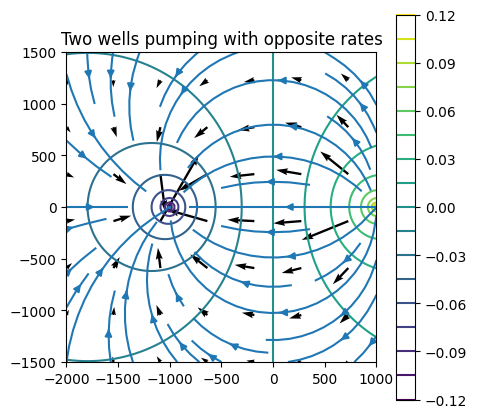

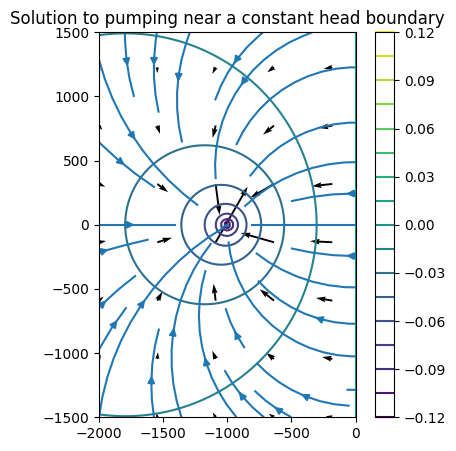

In [4]:
x_coords = np.linspace(-2000,1000,100)
y_coords = np.linspace(-1500,1500,100)
xc,yc = np.meshgrid(x_coords,y_coords)

# Location at which we want head change to be zero
x0, y0 = 0, 0

#Aquifer properties
T = 10 #m^2/day

xw1, yw1 = -1000, 0 #m
Q1 = 1.5 #m^3/day
xw2, yw2 = 1000, 0 #m
Q2 = -1.5 #m^3/day

well1_dh, well1_qix, well1_qiy = Thiem_dh(Q1,T,xw1,yw1,x0,y0,xc,yc)
well2_dh, well2_qix, well2_qiy = Thiem_dh(Q2,T,xw2,yw2,x0,y0,xc,yc)

dh_total = well1_dh + well2_dh
qix_total = well1_qix + well2_qix
qiy_total = well1_qiy + well2_qiy

# Create a figure object and axis object
fig, ax = plt.subplots(figsize=(5, 5))
#Add a contour plot to the axes
contp = ax.contour(xc, yc, dh_total,levels=20)
strmp = ax.streamplot(xc, yc, qix_total, qiy_total, density=0.5)
qfreq = 15
quiv = ax.quiver(xc[::qfreq,::qfreq],
                 yc[::qfreq,::qfreq],
                 qix_total[::qfreq,::qfreq],
                 qiy_total[::qfreq,::qfreq],)

ax.set_aspect('equal','box')
ax.set_title('Two wells pumping with opposite rates')
fig.colorbar(contp)
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
#Add a contour plot to the axes
contp = ax.contour(xc, yc, dh_total,levels=20)
strmp = ax.streamplot(xc, yc, qix_total, qiy_total, density=0.5)
qfreq = 15
quiv = ax.quiver(xc[::qfreq,::qfreq],
                 yc[::qfreq,::qfreq],
                 qix_total[::qfreq,::qfreq],
                 qiy_total[::qfreq,::qfreq],)

ax.set_aspect('equal','box')
ax.set_title('Solution to pumping near a constant head boundary')
ax.set_xlim(-2000,0)
fig.colorbar(contp)
plt.show()


## Example 3: Two wells with the same pumping rate

Note that for two wells with the same pumping rates, the line exactly halfway between them separates the flow field into two flow cells (i.e., there is a stagnation point exactly halfway between the wells.

As shown in the second figure, a no flow head boundary can be simulated for an analytical model by using this insight and placing an "image well" reflected across a constant head boundary.

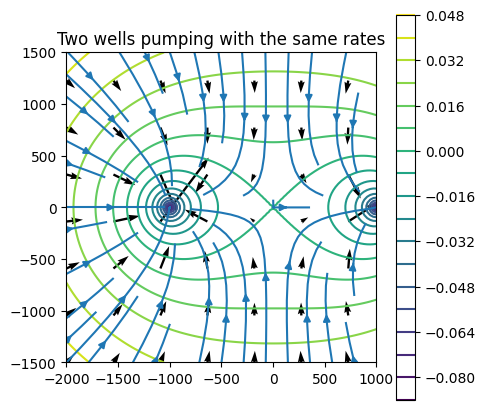

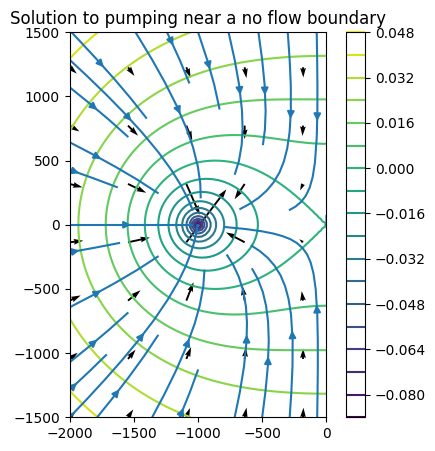

In [5]:

x_coords = np.linspace(-2000,1000,100)
y_coords = np.linspace(-1500,1500,100)
xc,yc = np.meshgrid(x_coords,y_coords)

# Location at which we want head change to be zero
x0, y0 = 0, 0

#Aquifer properties
T = 10 #m^2/day

xw1, yw1 = -1000, 0 #m
Q1 = 1.5 #m^3/day
xw2, yw2 = 1000, 0 #m
Q2 = 1.5 #m^3/day

well1_dh, well1_qix, well1_qiy = Thiem_dh(Q1,T,xw1,yw1,x0,y0,xc,yc)
well2_dh, well2_qix, well2_qiy = Thiem_dh(Q2,T,xw2,yw2,x0,y0,xc,yc)


dh_total = well1_dh + well2_dh
qix_total = well1_qix + well2_qix
qiy_total = well1_qiy + well2_qiy

# Create a figure object and axis object
fig, ax = plt.subplots(figsize=(5, 5))
#Add a contour plot to the axes
contp = ax.contour(xc, yc, dh_total,levels=20)
strmp = ax.streamplot(xc, yc, qix_total, qiy_total, density=0.5)
qfreq = 15
quiv = ax.quiver(xc[::qfreq,::qfreq],
                 yc[::qfreq,::qfreq],
                 qix_total[::qfreq,::qfreq],
                 qiy_total[::qfreq,::qfreq],)

ax.set_aspect('equal','box')
ax.set_title('Two wells pumping with the same rates')
fig.colorbar(contp)
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
#Add a contour plot to the axes
contp = ax.contour(xc, yc, dh_total,levels=20)
strmp = ax.streamplot(xc, yc, qix_total, qiy_total, density=0.5)
qfreq = 15
quiv = ax.quiver(xc[::qfreq,::qfreq],
                 yc[::qfreq,::qfreq],
                 qix_total[::qfreq,::qfreq],
                 qiy_total[::qfreq,::qfreq],)

ax.set_aspect('equal','box')
ax.set_title('Solution to pumping near a no flow boundary')
ax.set_xlim(-2000,0)
fig.colorbar(contp)
plt.show()


# Example 4: Transient Solution for flow near a boundary

The regional flow, Thiem, and Theis solution are each solutions, so they can each be added together to produce other scenarios. The example below shows head and flow vectors for a transient pumping test near a no-flow boundary at multiple points in time.

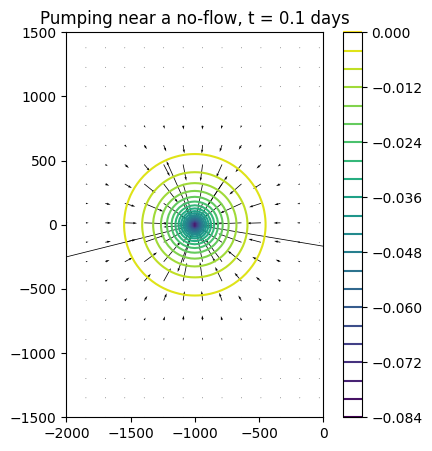

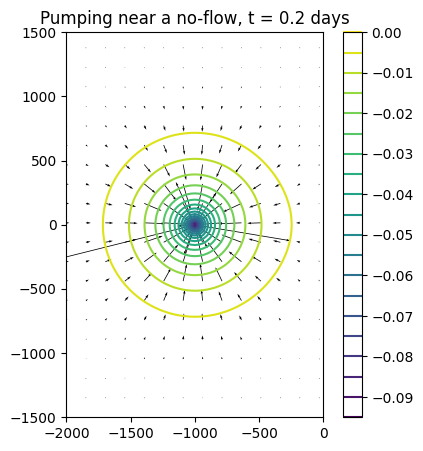

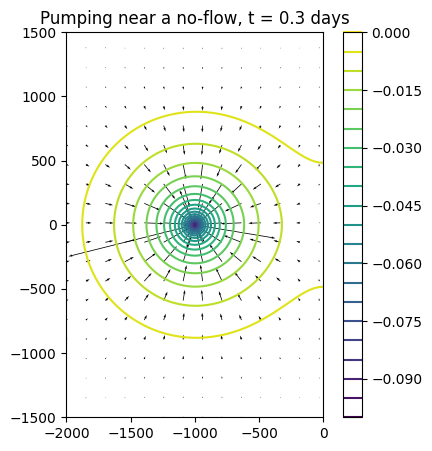

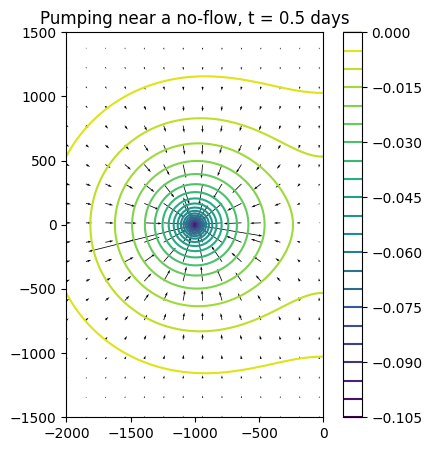

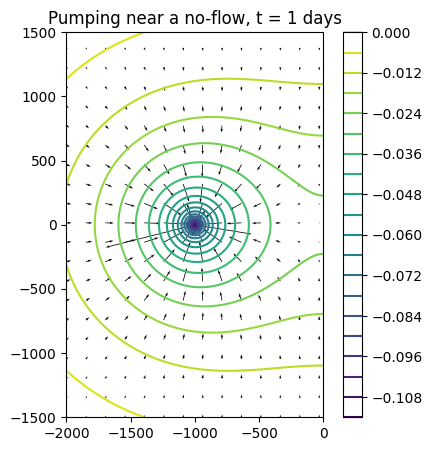

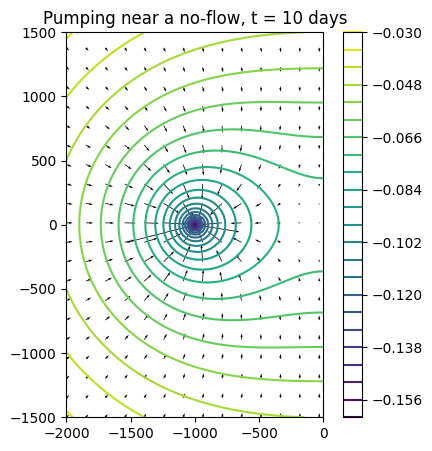

In [6]:
#Choose the range of space across which you want to plot your function 
#(2-D Solutions only)
x_coords = np.linspace(-2000,1000,100)
y_coords = np.linspace(-1500,1500,100)
xc,yc = np.meshgrid(x_coords,y_coords)

# Location at which we want head change to be zero
x0, y0 = 0, 0

#Aquifer properties
T = 10 #m^2/day
S = 1e-5 #unitless

xw1, yw1 = -1000, 0 #m
Q1 = 1.5 #m^3/day
xw2, yw2 = 1000, 0 #m
Q2 = 1.5 #m^3/day

tlist = [0.1, 0.2, 0.3, 0.5, 1, 10]
for t in tlist:
    well1_dh, well1_qix, well1_qiy = Theis_dh(Q1,T,S,xw1,yw1,xc,yc,t)
    well2_dh, well2_qix, well2_qiy = Theis_dh(Q2,T,S,xw2,yw2,xc,yc,t)
    dh_total = well1_dh + well2_dh
    qix_total = well1_qix + well2_qix
    qiy_total = well1_qiy + well2_qiy
    
    fig, ax = plt.subplots(figsize=(5, 5))
    #Add a contour plot to the axes
    contp = ax.contour(xc, yc, dh_total,levels=20)
    qfreq = 5
    quiv = ax.quiver(xc[::qfreq,::qfreq],
                     yc[::qfreq,::qfreq],
                     qix_total[::qfreq,::qfreq],
                     qiy_total[::qfreq,::qfreq],)
    
    ax.set_aspect('equal','box')
    ax.set_title(f"Pumping near a no-flow, t = {t} days")
    ax.set_xlim(-2000,0)
    fig.colorbar(contp)
    plt.show()
